# Eksplorasi Training 
**Notebook buat eksplorasi doang**

### Struktur Notebook:
1. Import Library
2. Konfigurasi
3. Load Dataset
4. Dataset Class & Transformasi
5. Modeling
6. Training & Evaluation
7. Hyperparameter Tuning

---
## 1. Import Library

In [19]:
import gc
import json
import random
import sys
import time
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import torch
import torch.nn as nn
import torchvision
import torchvision.models.segmentation as seg_models
import torchvision.transforms.functional as TF
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

# Cek versi library
print("Versi Environment")
print("-" * 60)
print(f"Python      : {sys.version.split()[0]}")
print(f"PyTorch     : {torch.__version__}")
print(f"Torchvision : {torchvision.__version__}")
print(f"NumPy       : {np.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"Optuna      : {optuna.__version__}")
print()

# Setup CUDA / GPU
cuda_ok = torch.cuda.is_available()
print(f"CUDA tersedia : {cuda_ok}")
if cuda_ok:
    print(f"GPU           : {torch.cuda.get_device_name(0)}")
    print(f"VRAM total    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
else:
    print("[PERINGATAN] GPU tidak terdeteksi, training akan berjalan di CPU.")

DEVICE = torch.device("cuda" if cuda_ok else "cpu")
print(f"Device aktif  : {DEVICE}")

Versi Environment
------------------------------------------------------------
Python      : 3.11.9
PyTorch     : 2.5.1+cu121
Torchvision : 0.20.1+cu121
NumPy       : 2.4.6
Matplotlib  : 3.11.2
Optuna      : 5.1.0

CUDA tersedia : True
GPU           : NVIDIA GeForce RTX 4060 Laptop GPU
VRAM total    : 8.6 GB
Device aktif  : cuda


---
## 2. Konfigurasi

### Cell 2.1 — Setup Path, Directory, dan Verifikasi Path

In [20]:
# Resolusi path root proyek secara dinamis agar aman di berbagai working directory
_cwd = Path.cwd().resolve()
if (_cwd / "data" / "camvid").exists():
    REPO_ROOT = _cwd
elif len(_cwd.parents) > 1 and (_cwd.parents[1] / "data" / "camvid").exists():
    REPO_ROOT = _cwd.parents[1]
else:
    REPO_ROOT = Path("__file__").resolve().parents[2]

CAMVID_DIR  = REPO_ROOT / "data" / "camvid"
SPLITS_DIR  = CAMVID_DIR / "splits"
WEIGHTS_DIR = REPO_ROOT / "src" / "deep_learning" / "weights"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

# Verifikasi keberadaan path utama
print("Verifikasi Path")
print("-" * 60)
print(f"REPO_ROOT   : {REPO_ROOT}  (exists={REPO_ROOT.exists()})")
print(f"CAMVID_DIR  : {CAMVID_DIR}  (exists={CAMVID_DIR.exists()})")
print(f"SPLITS_DIR  : {SPLITS_DIR}  (exists={SPLITS_DIR.exists()})")
print(f"WEIGHTS_DIR : {WEIGHTS_DIR}  (exists={WEIGHTS_DIR.exists()})")

assert CAMVID_DIR.exists(), f"CAMVID_DIR tidak ditemukan: {CAMVID_DIR}"
assert SPLITS_DIR.exists(), f"SPLITS_DIR tidak ditemukan: {SPLITS_DIR}"

Verifikasi Path
------------------------------------------------------------
REPO_ROOT   : C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3  (exists=True)
CAMVID_DIR  : C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\data\camvid  (exists=True)
SPLITS_DIR  : C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\data\camvid\splits  (exists=True)
WEIGHTS_DIR : C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\src\deep_learning\weights  (exists=True)


### Cell 2.2 — Konstanta Kelas, Palet Warna, Class Weight, dan Hyperparameter

In [21]:
# Konstanta kelas CamVid (11 kelas target + Void)
NUM_CLASSES  = 11
IGNORE_INDEX = 255

CLASS_NAMES = [
    "Sky", "Building", "Pole", "Road", "Pavement",
    "Tree", "SignSymbol", "Fence", "Car", "Pedestrian", "Bicyclist",
]

# Palet warna RGB standar untuk visualisasi 11 kelas
PALETTE = np.array([
    [128, 128, 128],  # 0: Sky
    [128,   0,   0],  # 1: Building
    [192, 192, 128],  # 2: Pole
    [128,  64, 128],  # 3: Road
    [  0,   0, 192],  # 4: Pavement
    [128, 128,   0],  # 5: Tree
    [192, 128, 128],  # 6: SignSymbol
    [ 64,  64, 128],  # 7: Fence
    [ 64,   0, 128],  # 8: Car
    [ 64,  64,   0],  # 9: Pedestrian
    [  0, 128, 192],  # 10: Bicyclist
], dtype=np.uint8)

# Class weights dari camvid_metadata.json (Median Frequency Balancing)
CLASS_WEIGHTS = torch.tensor([
    0.318185,  # Sky
    0.208198,  # Building
    5.092367,  # Pole
    0.174382,  # Road
    0.710338,  # Pavement
    0.417519,  # Tree
    4.537075,  # SignSymbol
    1.838648,  # Fence
    1.000000,  # Car
    6.605879,  # Pedestrian
    5.113338,  # Bicyclist
], dtype=torch.float32)

# Konstanta prapemrosesan & DataLoader
# 352 dan 480 keduanya habis dibagi 32 (syarat stride DeepLabv3+)
INPUT_H, INPUT_W = 352, 480
IMG_MEAN         = [0.485, 0.456, 0.406]  # Normalisasi ImageNet
IMG_STD          = [0.229, 0.224, 0.225]
BATCH_SIZE       = 4
NUM_WORKERS      = 0  # Aman untuk multiprocessing di Windows

# Konstanta training eksplorasi & tuning
EXPLORE_EPOCHS   = 10
LR               = 1e-4
WEIGHT_DECAY     = 1e-4
SANITY_STEPS     = 30

N_TRIALS         = 12
TRIAL_EPOCHS     = 8
BASE_SEED        = 42

print("Konfigurasi Konstanta")
print("-" * 60)
print(f"Jumlah kelas   : {NUM_CLASSES} ({', '.join(CLASS_NAMES)})")
print(f"Resolusi input : {INPUT_H} x {INPUT_W}")
print(f"Batch size     : {BATCH_SIZE} | Explore epochs : {EXPLORE_EPOCHS}")
print(f"Tuning setup   : {N_TRIALS} trials x {TRIAL_EPOCHS} epoch (seed={BASE_SEED})")

Konfigurasi Konstanta
------------------------------------------------------------
Jumlah kelas   : 11 (Sky, Building, Pole, Road, Pavement, Tree, SignSymbol, Fence, Car, Pedestrian, Bicyclist)
Resolusi input : 352 x 480
Batch size     : 4 | Explore epochs : 10
Tuning setup   : 12 trials x 8 epoch (seed=42)


### Cell 2.3 — Helper Visualisasi

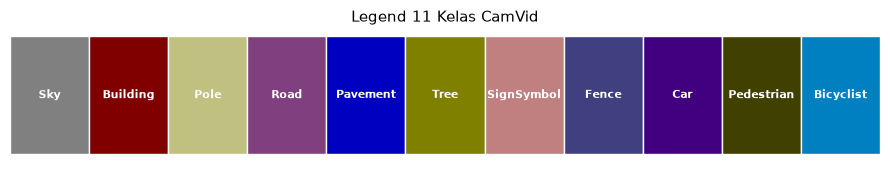

In [22]:
def mask_to_colormap(mask: np.ndarray) -> np.ndarray:
    """Konversi mask indeks (H, W) menjadi citra warna RGB (H, W, 3) menggunakan PALETTE."""
    color = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for cls_id, rgb in enumerate(PALETTE):
        color[mask == cls_id] = rgb
    # Piksel Void (255) dibiarkan hitam (0, 0, 0)
    return color


def show_sample(img: np.ndarray, mask: np.ndarray, title: str = "") -> None:
    """Tampilkan citra asli dan ground truth berwarna berdampingan."""
    color_mask = mask_to_colormap(mask)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(img)
    axes[0].set_title("Citra Asli")
    axes[0].axis("off")
    axes[1].imshow(color_mask)
    axes[1].set_title("Ground Truth (11 Kelas)")
    axes[1].axis("off")
    if title:
        fig.suptitle(title, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def show_legend() -> None:
    """Tampilkan legend warna 11 kelas CamVid."""
    fig, ax = plt.subplots(figsize=(9, 1.8))
    for i, (name, color) in enumerate(zip(CLASS_NAMES, PALETTE)):
        ax.barh(0, 1, left=i, color=np.array(color) / 255.0, edgecolor="white")
        ax.text(i + 0.5, 0, name, ha="center", va="center",
                fontsize=8, color="white", fontweight="bold")
    ax.set_xlim(0, NUM_CLASSES)
    ax.axis("off")
    ax.set_title("Legend 11 Kelas CamVid", fontsize=11)
    plt.tight_layout()
    plt.show()


show_legend()

---
## 3. Load Dataset

### Cell 3.1 — Baca File Split dan Verifikasi

In [23]:
def load_split(split_name: str):
    """Baca train.txt / val.txt / test.txt menjadi list pasangan (img_path, mask_path)."""
    split_file = SPLITS_DIR / f"{split_name}.txt"
    pairs = []
    with split_file.open("r", encoding="utf-8") as f:
        for line in f:
            rel_img, rel_mask = line.strip().split(",")
            pairs.append((CAMVID_DIR / rel_img, CAMVID_DIR / rel_mask))
    return pairs


train_pairs = load_split("train")
val_pairs   = load_split("val")
test_pairs  = load_split("test")

print("Ringkasan Split Dataset")
print("-" * 60)
print(f"Train : {len(train_pairs)} pasang")
print(f"Val   : {len(val_pairs)} pasang")
print(f"Test  : {len(test_pairs)} pasang")
print(f"Total : {len(train_pairs) + len(val_pairs) + len(test_pairs)} pasang")

# Verifikasi keberadaan seluruh file di disk
all_pairs = train_pairs + val_pairs + test_pairs
missing = [(img, msk) for img, msk in all_pairs if not img.exists() or not msk.exists()]
assert len(missing) == 0, f"Ditemukan {len(missing)} file hilang, contoh: {missing[0]}"
print("[OK] Seluruh pasangan citra dan mask ditemukan di disk.")

Ringkasan Split Dataset
------------------------------------------------------------
Train : 421 pasang
Val   : 140 pasang
Test  : 140 pasang
Total : 701 pasang
[OK] Seluruh pasangan citra dan mask ditemukan di disk.


### Cell 3.2 — Visualisasi 3 Sampel dari Train

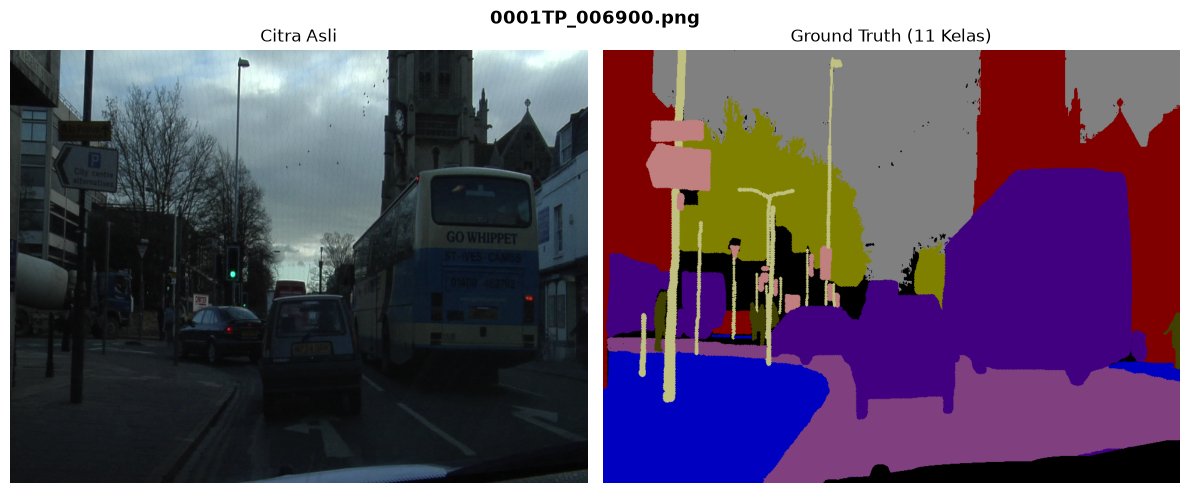

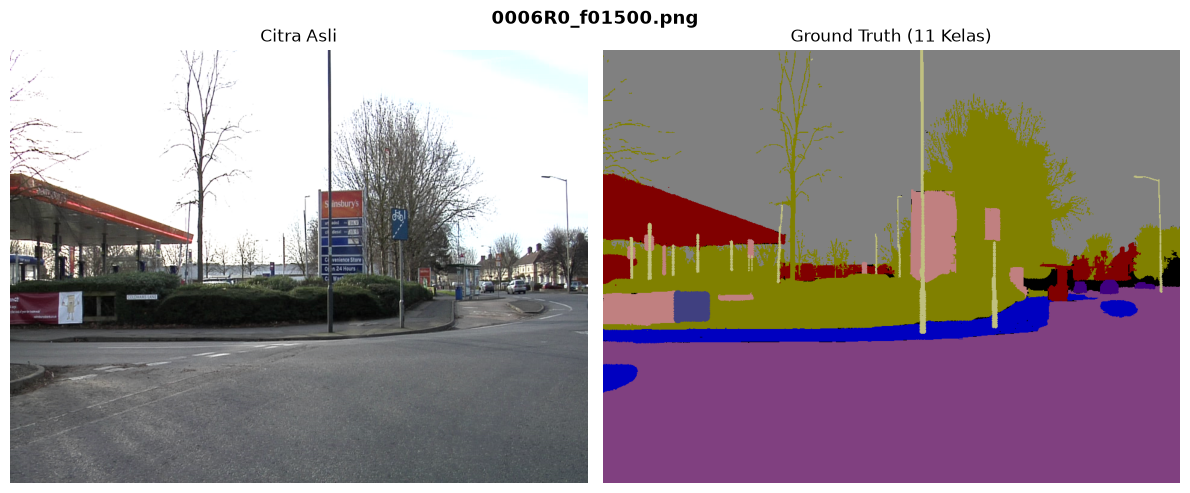

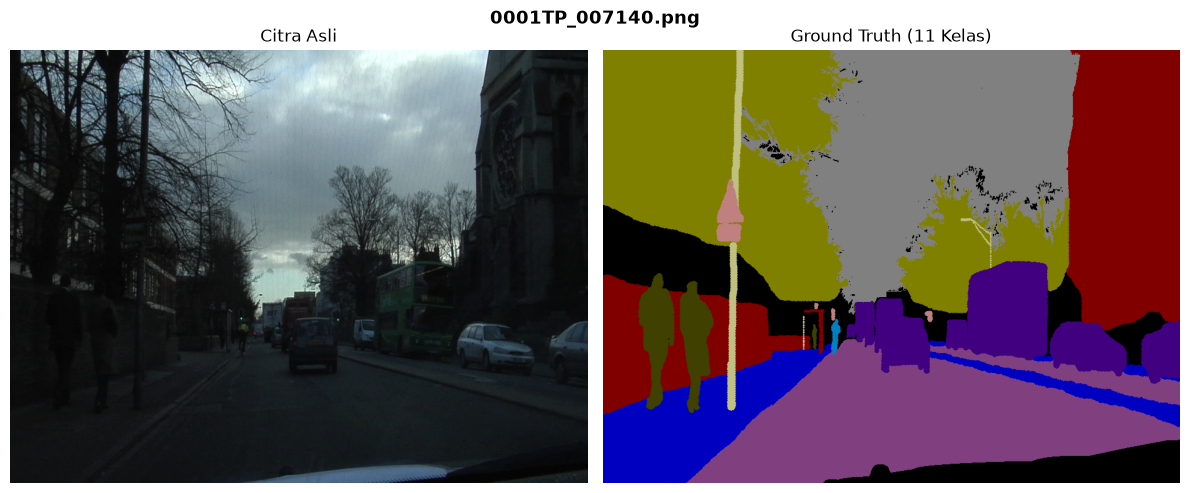

[OK] Verifikasi nilai mask berhasil: semua nilai dalam rentang {0..10, 255}.


In [24]:
random.seed(0)
samples = random.sample(train_pairs, 3)
valid_set = set(range(NUM_CLASSES)) | {IGNORE_INDEX}

for img_path, mask_path in samples:
    img  = np.array(Image.open(img_path).convert("RGB"))
    mask = np.array(Image.open(mask_path))

    # Pastikan seluruh nilai indeks kelas pada mask valid
    unique_vals = np.unique(mask)
    assert set(unique_vals.tolist()).issubset(valid_set), f"Nilai ilegal di mask: {unique_vals}"

    show_sample(img, mask, title=img_path.name)

print("[OK] Verifikasi nilai mask berhasil: semua nilai dalam rentang {0..10, 255}.")

### Cell 3.3 — Statistik Kelas Distribusi

Distribusi Piksel per Kelas (701 Citra)
------------------------------------------------------------
Kelas                  Piksel        %   Class Weight
------------------------------------------------------------
Sky                76,801,167    16.34%         0.3182
Building          117,373,718    24.98%         0.2082
Pole                4,798,742     1.02%         5.0924
Road              140,535,728    29.90%         0.1744
Pavement           33,614,414     7.15%         0.7103
Tree               54,258,673    11.55%         0.4175
SignSymbol          5,224,247     1.11%         4.5371
Fence               6,921,061     1.47%         1.8386
Car                24,436,957     5.20%         1.0000
Pedestrian          3,402,909     0.72%         6.6059
Bicyclist           2,591,222     0.55%         5.1133


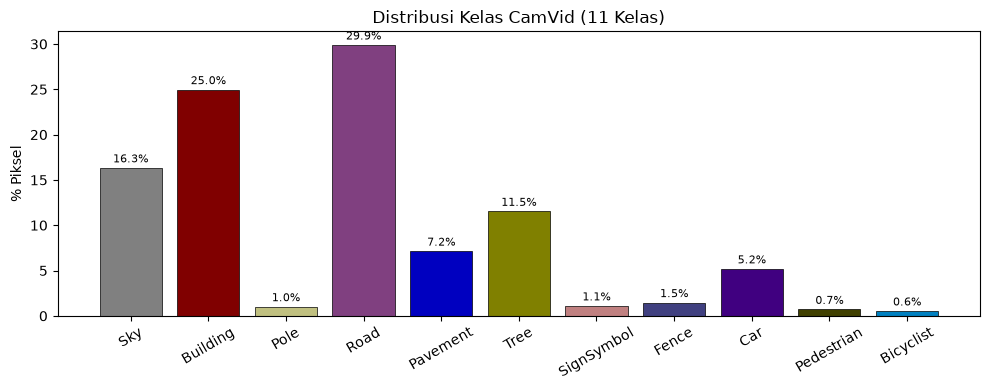

In [25]:
with (SPLITS_DIR / "camvid_metadata.json").open("r", encoding="utf-8") as f:
    meta = json.load(f)

pixel_counts = np.array(meta["pixel_counts"], dtype=np.float64)
total_pixels = pixel_counts.sum()
percentages  = pixel_counts / total_pixels * 100

print("Distribusi Piksel per Kelas (701 Citra)")
print("-" * 60)
print(f"{'Kelas':<14} {'Piksel':>14} {'%':>8}  {'Class Weight':>13}")
print("-" * 60)
for i, (name, pct, w) in enumerate(zip(CLASS_NAMES, percentages, meta["median_freq_weights"])):
    print(f"{name:<14} {int(pixel_counts[i]):>14,} {pct:>8.2f}%  {w:>13.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
colors = [np.array(c) / 255.0 for c in PALETTE]
bars = ax.bar(CLASS_NAMES, percentages, color=colors, edgecolor="black", linewidth=0.5)
ax.set_ylabel("% Piksel")
ax.set_title("Distribusi Kelas CamVid (11 Kelas)")
ax.tick_params(axis="x", rotation=30)
for bar, pct in zip(bars, percentages):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f"{pct:.1f}%", ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()

---
## 4. Dataset Class & Transformasi

In [26]:
class CamVidDataset(Dataset):
    """Dataset CamVid yang membaca pasangan path dari splits/*.txt."""

    def __init__(self, pairs, augment: bool = False):
        self.pairs   = pairs
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        # Baca citra sebagai RGB dan mask sebagai grayscale indeks kelas
        img  = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path)

        # Augmentasi sinkron (hanya saat training)
        if self.augment:
            if random.random() > 0.5:
                img  = TF.hflip(img)
                mask = TF.hflip(mask)

        # Resize: BILINEAR untuk citra, NEAREST untuk mask agar indeks kelas tetap diskret
        img  = TF.resize(img, (INPUT_H, INPUT_W),
                         interpolation=TF.InterpolationMode.BILINEAR)
        mask = TF.resize(mask, (INPUT_H, INPUT_W),
                         interpolation=TF.InterpolationMode.NEAREST)

        # Konversi ke tensor & normalisasi ImageNet
        img  = TF.normalize(TF.to_tensor(img), IMG_MEAN, IMG_STD)
        mask = torch.as_tensor(np.array(mask), dtype=torch.long)
        return img, mask


train_dataset = CamVidDataset(train_pairs, augment=True)
val_dataset   = CamVidDataset(val_pairs,   augment=False)

# drop_last=True wajib pada train_loader agar BatchNorm ASPPPooling tidak error saat batch sisa=1
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          drop_last=True, num_workers=NUM_WORKERS, pin_memory=cuda_ok)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=cuda_ok)

print("DataLoader Siap")
print("-" * 60)
print(f"Train loader : {len(train_loader)} batch x {BATCH_SIZE} = {len(train_loader) * BATCH_SIZE} sampel efektif")
print(f"Val loader   : {len(val_loader)} batch (total {len(val_dataset)} sampel)")

imgs, masks = next(iter(train_loader))
print(f"Shape imgs   : {imgs.shape}  dtype: {imgs.dtype}")
print(f"Shape masks  : {masks.shape} dtype: {masks.dtype}")
print(f"Nilai unik mask batch pertama: {masks.unique().tolist()}")

DataLoader Siap
------------------------------------------------------------
Train loader : 105 batch x 4 = 420 sampel efektif
Val loader   : 35 batch (total 140 sampel)
Shape imgs   : torch.Size([4, 3, 352, 480])  dtype: torch.float32
Shape masks  : torch.Size([4, 352, 480]) dtype: torch.int64
Nilai unik mask batch pertama: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 255]


---
## 5. Modeling

### Cell 5.1 — Load Model DeepLabv3+ Pretrained ImageNet

In [27]:
def build_deeplabv3_mobilenet(num_classes: int = NUM_CLASSES) -> nn.Module:
    """
    Memuat DeepLabv3+ dengan backbone MobileNetV3-Large pretrained ImageNet,
    lalu mengganti classifier head agar outputnya sesuai num_classes.
    """
    model = seg_models.deeplabv3_mobilenet_v3_large(
        weights=seg_models.DeepLabV3_MobileNet_V3_Large_Weights.DEFAULT
    )

    in_ch = model.classifier[0].convs[0][0].in_channels
    model.classifier = seg_models.deeplabv3.DeepLabHead(in_ch, num_classes)

    if model.aux_classifier is not None:
        in_ch_aux = model.aux_classifier[0].in_channels
        model.aux_classifier = seg_models.fcn.FCNHead(in_ch_aux, num_classes)

    return model


model = build_deeplabv3_mobilenet(num_classes=NUM_CLASSES).to(DEVICE)
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Arsitektur Model")
print("-" * 60)
print(f"Model              : DeepLabv3+ MobileNetV3-Large")
print(f"Device             : {DEVICE}")
print(f"Total parameter    : {total_params:,}")
print(f"Parameter trainable: {trainable_params:,}")

Arsitektur Model
------------------------------------------------------------
Model              : DeepLabv3+ MobileNetV3-Large
Device             : cuda
Total parameter    : 11,026,648
Parameter trainable: 11,026,648


### Cell 5.2 — Define Loss, Optimizer, dan Scheduler

In [28]:
criterion = nn.CrossEntropyLoss(
    weight=CLASS_WEIGHTS.to(DEVICE),
    ignore_index=IGNORE_INDEX,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=3
)

print("Konfigurasi Training Dasar")
print("-" * 60)
print(f"Loss      : CrossEntropyLoss (class weighted, ignore_index={IGNORE_INDEX})")
print(f"Optimizer : AdamW (lr={LR}, weight_decay={WEIGHT_DECAY})")
print("Scheduler : ReduceLROnPlateau (mode=min, factor=0.5, patience=3)")

Konfigurasi Training Dasar
------------------------------------------------------------
Loss      : CrossEntropyLoss (class weighted, ignore_index=255)
Optimizer : AdamW (lr=0.0001, weight_decay=0.0001)
Scheduler : ReduceLROnPlateau (mode=min, factor=0.5, patience=3)


### Cell 5.3 — Sanity Check (Single-Batch Overfit Test)

Sanity Check: Single-Batch Overfit Test
------------------------------------------------------------
  Step  5/30 - Loss: 0.6864
  Step 10/30 - Loss: 0.3946
  Step 15/30 - Loss: 0.2910
  Step 20/30 - Loss: 0.2399
  Step 25/30 - Loss: 0.1973
  Step 30/30 - Loss: 0.1793

[PASS] Loss turun dari 2.4115 -> 0.1793


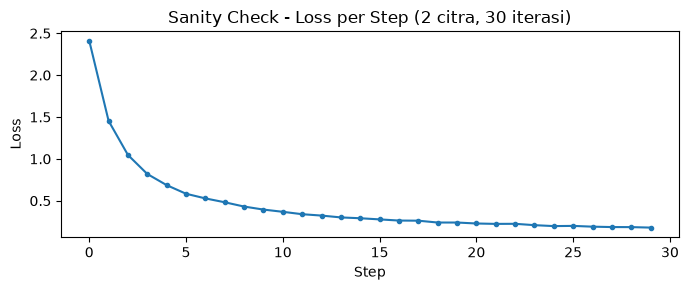

In [29]:
print("Sanity Check: Single-Batch Overfit Test")
print("-" * 60)

tiny_loader = DataLoader(
    CamVidDataset(train_pairs[:2], augment=False),
    batch_size=2, shuffle=False, num_workers=0,
)
imgs_sanity, masks_sanity = next(iter(tiny_loader))
imgs_sanity  = imgs_sanity.to(DEVICE)
masks_sanity = masks_sanity.to(DEVICE)

sanity_model = build_deeplabv3_mobilenet(NUM_CLASSES).to(DEVICE)
sanity_opt   = torch.optim.AdamW(sanity_model.parameters(), lr=1e-3)

losses_sanity = []
sanity_model.train()
for step in range(SANITY_STEPS):
    sanity_opt.zero_grad()
    output = sanity_model(imgs_sanity)["out"]
    loss   = criterion(output, masks_sanity)
    loss.backward()
    sanity_opt.step()
    losses_sanity.append(loss.item())
    if (step + 1) % 5 == 0:
        print(f"  Step {step + 1:2d}/{SANITY_STEPS} - Loss: {loss.item():.4f}")

print()
if losses_sanity[-1] < losses_sanity[0] * 0.5:
    print(f"[PASS] Loss turun dari {losses_sanity[0]:.4f} -> {losses_sanity[-1]:.4f}")
else:
    print(f"[FAIL] Loss tidak turun signifikan ({losses_sanity[0]:.4f} -> {losses_sanity[-1]:.4f})")

plt.figure(figsize=(7, 3))
plt.plot(losses_sanity, marker="o", markersize=3)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title(f"Sanity Check - Loss per Step (2 citra, {SANITY_STEPS} iterasi)")
plt.tight_layout()
plt.show()

del sanity_model, sanity_opt, imgs_sanity, masks_sanity
if cuda_ok:
    torch.cuda.empty_cache()

---
## 6. Training & Evaluation

### Cell 6.1 — Fungsi Metriks (Pixel Accuracy & mIoU)

In [30]:
def compute_metrics(pred_mask: torch.Tensor, true_mask: torch.Tensor,
                    num_classes: int = NUM_CLASSES,
                    ignore_index: int = IGNORE_INDEX):
    """
    Hitung Global Pixel Accuracy dan Mean IoU untuk satu batch.
    pred_mask : (B, H, W) indeks kelas hasil argmax
    true_mask : (B, H, W) ground truth indeks kelas
    """
    valid  = true_mask != ignore_index
    pred   = pred_mask[valid]
    target = true_mask[valid]

    pixel_acc = (pred == target).float().mean().item()

    iou_list = []
    for cls in range(num_classes):
        pred_cls     = pred == cls
        target_cls   = target == cls
        intersection = (pred_cls & target_cls).sum().item()
        union        = (pred_cls | target_cls).sum().item()
        if union > 0:
            iou_list.append(intersection / union)
    mean_iou = float(np.mean(iou_list)) if iou_list else 0.0
    return pixel_acc, mean_iou


def evaluate_validation(model_eval: nn.Module, loader: DataLoader, loss_fn: nn.Module):
    """
    Evaluasi seluruh validation set secara global (akumulasi intersection & union),
    sehingga hasil mIoU konsisten dan tidak bergantung pada ukuran batch.
    """
    model_eval.eval()
    val_loss_sum  = 0.0
    total_correct = 0
    total_valid   = 0
    intersections = torch.zeros(NUM_CLASSES, dtype=torch.float64)
    unions        = torch.zeros(NUM_CLASSES, dtype=torch.float64)

    with torch.no_grad():
        for imgs_b, masks_b in loader:
            imgs_b, masks_b = imgs_b.to(DEVICE), masks_b.to(DEVICE)
            output   = model_eval(imgs_b)["out"]
            loss     = loss_fn(output, masks_b)
            val_loss_sum += loss.item()

            pred_cls = output.argmax(dim=1)
            valid    = masks_b != IGNORE_INDEX
            pred_v   = pred_cls[valid]
            target_v = masks_b[valid]

            total_correct += (pred_v == target_v).sum().item()
            total_valid   += valid.sum().item()

            for cls in range(NUM_CLASSES):
                p_c = pred_v == cls
                t_c = target_v == cls
                intersections[cls] += (p_c & t_c).sum().item()
                unions[cls]        += (p_c | t_c).sum().item()

    avg_loss = val_loss_sum / len(loader)
    acc      = total_correct / max(total_valid, 1)
    valid_c  = unions > 0
    miou     = float((intersections[valid_c] / unions[valid_c]).mean().item()) if valid_c.any() else 0.0
    return avg_loss, acc, miou


print("[OK] Fungsi compute_metrics dan evaluate_validation siap.")

[OK] Fungsi compute_metrics dan evaluate_validation siap.


### Cell 6.2 — Training Loop Mini (10 Epoch)

In [31]:
print(f"Training Eksplorasi ({EXPLORE_EPOCHS} Epoch)")
print("-" * 60)

history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_miou": []}

for epoch in range(1, EXPLORE_EPOCHS + 1):
    model.train()
    train_loss_sum = 0.0
    for imgs_b, masks_b in tqdm(train_loader, desc=f"Epoch {epoch}/{EXPLORE_EPOCHS} [Train]", leave=False):
        imgs_b, masks_b = imgs_b.to(DEVICE), masks_b.to(DEVICE)
        optimizer.zero_grad()
        output = model(imgs_b)["out"]
        loss   = criterion(output, masks_b)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item()

    avg_train_loss = train_loss_sum / len(train_loader)
    avg_val_loss, avg_val_acc, avg_val_miou = evaluate_validation(model, val_loader, criterion)

    scheduler.step(avg_val_loss)

    history["train_loss"].append(avg_train_loss)
    history["val_loss"].append(avg_val_loss)
    history["val_acc"].append(avg_val_acc)
    history["val_miou"].append(avg_val_miou)

    print(f"Epoch {epoch:2d}/{EXPLORE_EPOCHS} "
          f"| Train Loss: {avg_train_loss:.4f} "
          f"| Val Loss: {avg_val_loss:.4f} "
          f"| Val Acc: {avg_val_acc * 100:.2f}% "
          f"| Val mIoU: {avg_val_miou * 100:.2f}%")

print("\n[OK] Training eksplorasi selesai.")

Training Eksplorasi (10 Epoch)
------------------------------------------------------------


Epoch  1/10 | Train Loss: 1.1747 | Val Loss: 0.8030 | Val Acc: 79.51% | Val mIoU: 48.85%


Epoch  2/10 | Train Loss: 0.7367 | Val Loss: 0.6403 | Val Acc: 82.77% | Val mIoU: 53.43%


Epoch  3/10 | Train Loss: 0.6029 | Val Loss: 0.5586 | Val Acc: 83.41% | Val mIoU: 54.76%


Epoch  4/10 | Train Loss: 0.5361 | Val Loss: 0.5245 | Val Acc: 84.37% | Val mIoU: 56.10%


Epoch  5/10 | Train Loss: 0.4854 | Val Loss: 0.4908 | Val Acc: 85.68% | Val mIoU: 58.50%


Epoch  6/10 | Train Loss: 0.4504 | Val Loss: 0.4710 | Val Acc: 85.96% | Val mIoU: 59.07%


Epoch  7/10 | Train Loss: 0.4225 | Val Loss: 0.4591 | Val Acc: 85.34% | Val mIoU: 57.87%


Epoch  8/10 | Train Loss: 0.4003 | Val Loss: 0.4417 | Val Acc: 85.69% | Val mIoU: 59.40%


Epoch  9/10 | Train Loss: 0.3841 | Val Loss: 0.4361 | Val Acc: 86.19% | Val mIoU: 59.60%


Epoch 10/10 | Train Loss: 0.3643 | Val Loss: 0.4322 | Val Acc: 86.42% | Val mIoU: 60.03%

[OK] Training eksplorasi selesai.


### Cell 6.3 — Plot Loss & Metrik

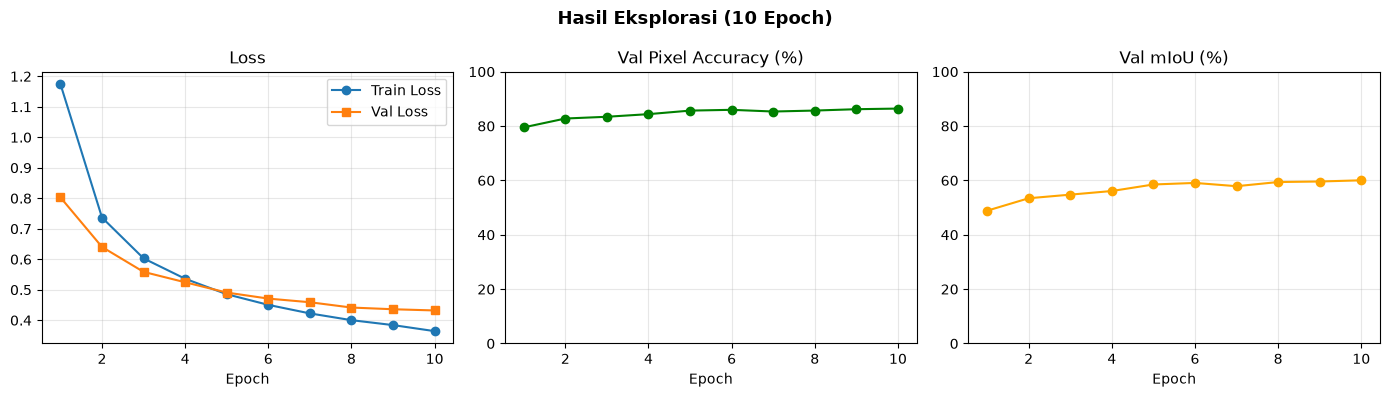

Grafik disimpan ke: C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\src\deep_learning\weights\explore_loss_curve.png


In [32]:
epochs_range = range(1, EXPLORE_EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].plot(epochs_range, history["train_loss"], label="Train Loss", marker="o")
axes[0].plot(epochs_range, history["val_loss"],   label="Val Loss",   marker="s")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, [v * 100 for v in history["val_acc"]], marker="o", color="green")
axes[1].set_title("Val Pixel Accuracy (%)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylim(0, 100)
axes[1].grid(alpha=0.3)

axes[2].plot(epochs_range, [v * 100 for v in history["val_miou"]], marker="o", color="orange")
axes[2].set_title("Val mIoU (%)")
axes[2].set_xlabel("Epoch")
axes[2].set_ylim(0, 100)
axes[2].grid(alpha=0.3)

plt.suptitle(f"Hasil Eksplorasi ({EXPLORE_EPOCHS} Epoch)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(WEIGHTS_DIR / "explore_loss_curve.png", dpi=120)
plt.show()

print(f"Grafik disimpan ke: {WEIGHTS_DIR / 'explore_loss_curve.png'}")

### Cell 6.4 — Visualisasi Hasil Prediksi vs Ground Truth

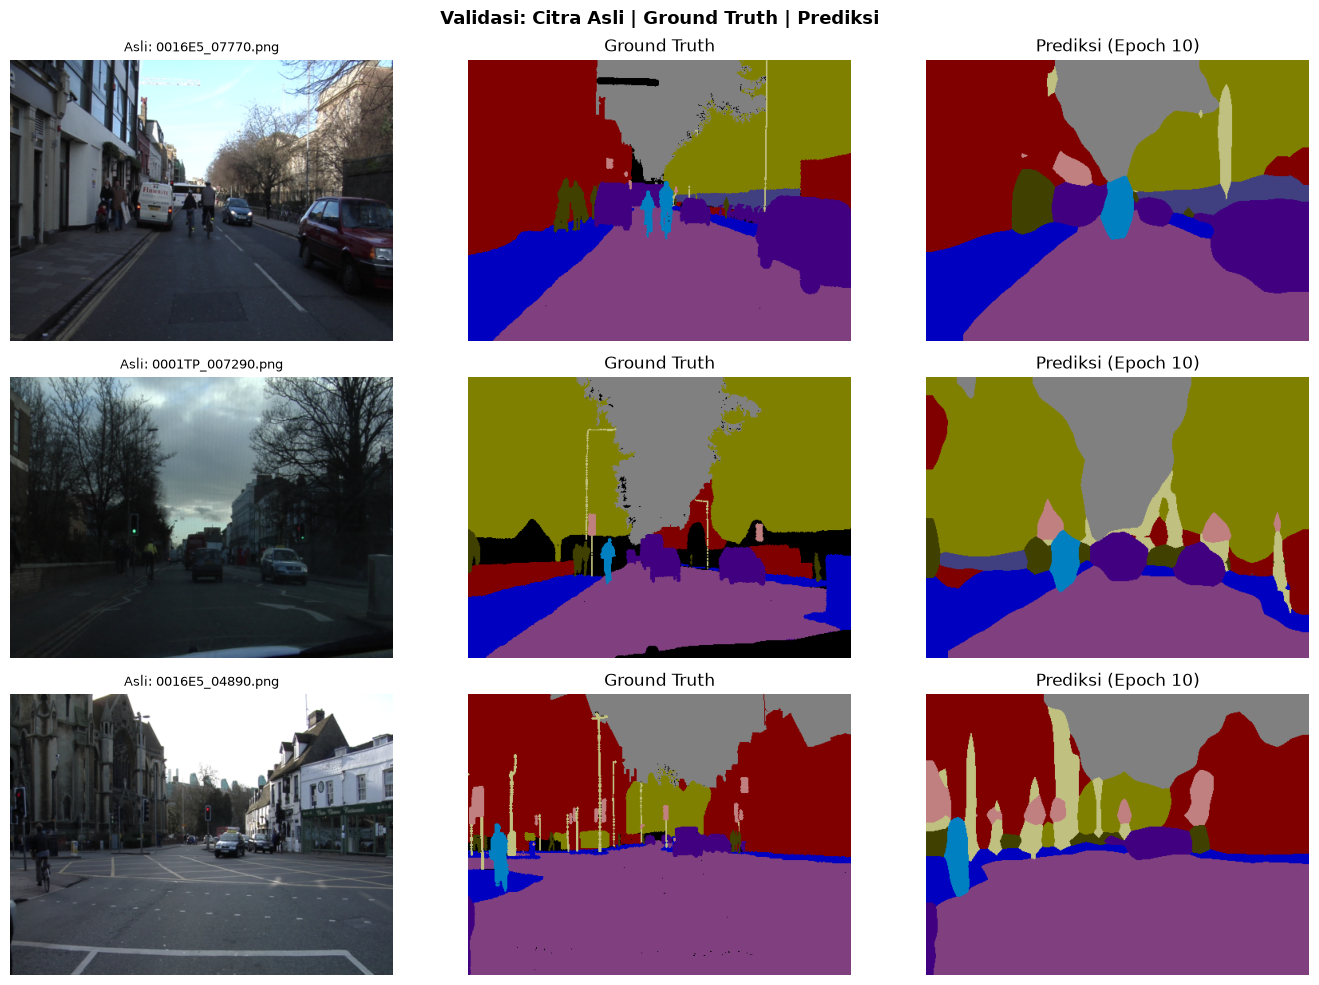

Visualisasi disimpan ke: C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\src\deep_learning\weights\explore_predictions.png


In [33]:
model.eval()
sample_dataset = CamVidDataset(val_pairs[:3], augment=False)

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
fig.suptitle("Validasi: Citra Asli | Ground Truth | Prediksi", fontsize=13, fontweight="bold")

mean_t = torch.tensor(IMG_MEAN).view(3, 1, 1)
std_t  = torch.tensor(IMG_STD).view(3, 1, 1)

for row, (img_path, _) in enumerate(val_pairs[:3]):
    img_tensor, mask_tensor = sample_dataset[row]

    with torch.no_grad():
        output   = model(img_tensor.unsqueeze(0).to(DEVICE))["out"]
        pred_cls = output.argmax(dim=1).squeeze(0).cpu().numpy()

    img_display = np.clip((img_tensor * std_t + mean_t).permute(1, 2, 0).numpy(), 0, 1)
    gt_color    = mask_to_colormap(mask_tensor.numpy())
    pred_color  = mask_to_colormap(pred_cls)

    axes[row][0].imshow(img_display)
    axes[row][0].set_title(f"Asli: {img_path.name}", fontsize=9)
    axes[row][0].axis("off")

    axes[row][1].imshow(gt_color)
    axes[row][1].set_title("Ground Truth")
    axes[row][1].axis("off")

    axes[row][2].imshow(pred_color)
    axes[row][2].set_title(f"Prediksi (Epoch {EXPLORE_EPOCHS})")
    axes[row][2].axis("off")

plt.tight_layout()
plt.savefig(WEIGHTS_DIR / "explore_predictions.png", dpi=120)
plt.show()

print(f"Visualisasi disimpan ke: {WEIGHTS_DIR / 'explore_predictions.png'}")

### Cell 6.5 — Simpan Checkpoint Eksplorasi

In [34]:
checkpoint_path = WEIGHTS_DIR / "explore_checkpoint.pth"

torch.save({
    "epoch":           EXPLORE_EPOCHS,
    "model_state":     model.state_dict(),
    "optimizer_state": optimizer.state_dict(),
    "history":         history,
    "num_classes":     NUM_CLASSES,
    "input_size":      (INPUT_H, INPUT_W),
}, checkpoint_path)

print(f"Checkpoint eksplorasi disimpan ke: {checkpoint_path}\n")
print("Ringkasan Hasil Eksplorasi")
print("-" * 60)
print(f"  Epoch terakhir  : {EXPLORE_EPOCHS}")
print(f"  Train Loss      : {history['train_loss'][-1]:.4f}")
print(f"  Val Loss        : {history['val_loss'][-1]:.4f}")
print(f"  Val Accuracy    : {history['val_acc'][-1] * 100:.2f}%")
print(f"  Val mIoU        : {history['val_miou'][-1] * 100:.2f}%")

Checkpoint eksplorasi disimpan ke: C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\src\deep_learning\weights\explore_checkpoint.pth

Ringkasan Hasil Eksplorasi
------------------------------------------------------------
  Epoch terakhir  : 10
  Train Loss      : 0.3643
  Val Loss        : 0.4322
  Val Accuracy    : 86.42%
  Val mIoU        : 60.03%


---
## 7. Hyperparameter Tuning

### Cell 7.1 — Hyperparameter Tuning with Bayesian Optimization

In [35]:
def set_seed(seed: int = BASE_SEED) -> None:
    """Set seed agar perbandingan antar-trial adil dan reproducible."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def objective(trial: optuna.Trial) -> float:
    """Fungsi objektif Optuna: mengembalikan Val mIoU terbaik dari satu trial."""
    set_seed(BASE_SEED)

    # Sampling ruang pencarian hyperparameter
    lr                = trial.suggest_float("lr", 5e-5, 1e-3, log=True)
    weight_decay      = trial.suggest_float("weight_decay", 1e-5, 1e-2, log=True)
    batch_size        = trial.suggest_categorical("batch_size", [4, 8])
    scheduler_name    = trial.suggest_categorical("scheduler", ["plateau", "cosine"])
    use_class_weights = trial.suggest_categorical("use_class_weights", [True, False])

    t_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          drop_last=True, num_workers=NUM_WORKERS, pin_memory=cuda_ok)
    v_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=cuda_ok)

    trial_model = build_deeplabv3_mobilenet(NUM_CLASSES).to(DEVICE)
    loss_weight = CLASS_WEIGHTS.to(DEVICE) if use_class_weights else None
    trial_crit  = nn.CrossEntropyLoss(weight=loss_weight, ignore_index=IGNORE_INDEX)
    trial_opt   = torch.optim.AdamW(trial_model.parameters(), lr=lr, weight_decay=weight_decay)

    if scheduler_name == "plateau":
        trial_sched = torch.optim.lr_scheduler.ReduceLROnPlateau(
            trial_opt, mode="max", factor=0.5, patience=2
        )
    else:
        trial_sched = torch.optim.lr_scheduler.CosineAnnealingLR(
            trial_opt, T_max=TRIAL_EPOCHS, eta_min=1e-6
        )

    best_val_miou = 0.0
    best_val_acc  = 0.0
    t0 = time.time()

    try:
        for epoch in range(1, TRIAL_EPOCHS + 1):
            trial_model.train()
            for imgs_b, masks_b in t_loader:
                imgs_b, masks_b = imgs_b.to(DEVICE), masks_b.to(DEVICE)
                trial_opt.zero_grad()
                out  = trial_model(imgs_b)["out"]
                loss = trial_crit(out, masks_b)
                loss.backward()
                trial_opt.step()

            _, val_acc, val_miou = evaluate_validation(trial_model, v_loader, trial_crit)

            if scheduler_name == "plateau":
                trial_sched.step(val_miou)
            else:
                trial_sched.step()

            if val_miou > best_val_miou:
                best_val_miou = val_miou
                best_val_acc  = val_acc

            trial.report(val_miou, step=epoch)
            if trial.should_prune():
                print(f"[Trial {trial.number:2d}] Pruned di epoch {epoch} (mIoU={val_miou * 100:.2f}%)")
                raise optuna.TrialPruned()

        trial.set_user_attr("best_val_acc", round(best_val_acc, 4))
        trial.set_user_attr("duration_sec", round(time.time() - t0, 1))
        print(f"[Trial {trial.number:2d}] Selesai ({time.time() - t0:.1f}s) | "
              f"Val mIoU={best_val_miou * 100:.2f}% | Val Acc={best_val_acc * 100:.2f}% | "
              f"lr={lr:.2e}, wd={weight_decay:.2e}, bs={batch_size}, sched={scheduler_name}, cw={use_class_weights}")
        return best_val_miou
    finally:
        del trial_model, trial_opt, trial_sched, trial_crit, t_loader, v_loader
        gc.collect()
        if cuda_ok:
            torch.cuda.empty_cache()


print(f"[OK] Fungsi objektif Bayesian Optimization siap ({N_TRIALS} trials x {TRIAL_EPOCHS} epoch).")

[OK] Fungsi objektif Bayesian Optimization siap (12 trials x 8 epoch).


### Cell 7.2 — Jalankan Bayesian Optimization

In [36]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

sampler = optuna.samplers.TPESampler(seed=BASE_SEED)
pruner  = optuna.pruners.MedianPruner(n_startup_trials=4, n_warmup_steps=3)

study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    pruner=pruner,
    study_name="camvid_deeplabv3_bo",
)

print(f"Memulai Bayesian Optimization ({N_TRIALS} trials)")
print("-" * 60)
study.optimize(objective, n_trials=N_TRIALS)

print("\nHasil Terbaik Bayesian Optimization")
print("-" * 60)
print(f"  Best Trial    : #{study.best_trial.number}")
print(f"  Best Val mIoU : {study.best_value * 100:.2f}%")
print(f"  Best Val Acc  : {study.best_trial.user_attrs.get('best_val_acc', 0.0) * 100:.2f}%")
print("  Best Params   :")
for k, v in study.best_params.items():
    print(f"    - {k:<18}: {v}")

print("\nRingkasan Seluruh Trial")
print("-" * 64)
print(f"{'Trial':>5} {'State':<9} {'mIoU':>7} {'lr':>9} {'wd':>9} {'bs':>3} {'sched':<7} {'cw':<5}")
print("-" * 64)
sorted_trials = sorted(
    study.trials,
    key=lambda t: t.value if t.value is not None else -1.0,
    reverse=True,
)
for t in sorted_trials:
    val_str = f"{t.value * 100:6.2f}%" if t.value is not None else "   N/A "
    p = t.params
    print(f"{t.number:5d} {t.state.name:<9} {val_str} {p.get('lr', 0):9.2e} "
          f"{p.get('weight_decay', 0):9.2e} {p.get('batch_size', 0):3d} "
          f"{p.get('scheduler', '-'):<7} {str(p.get('use_class_weights', '-')):<5}")

Memulai Bayesian Optimization (12 trials)
------------------------------------------------------------
[Trial  0] Selesai (313.0s) | Val mIoU=66.36% | Val Acc=91.77% | lr=1.54e-04, wd=7.11e-03, bs=4, sched=plateau, cw=False
[Trial  1] Selesai (240.5s) | Val mIoU=66.48% | Val Acc=92.08% | lr=3.03e-04, wd=1.33e-03, bs=8, sched=plateau, cw=False
[Trial  2] Selesai (271.8s) | Val mIoU=65.83% | Val Acc=91.68% | lr=1.24e-04, wd=3.75e-04, bs=4, sched=plateau, cw=False
[Trial  3] Selesai (234.0s) | Val mIoU=60.44% | Val Acc=86.14% | lr=1.96e-04, wd=2.27e-03, bs=8, sched=plateau, cw=True
[Trial  4] Pruned di epoch 3 (mIoU=53.07%)
[Trial  5] Pruned di epoch 3 (mIoU=46.82%)
[Trial  6] Selesai (276.0s) | Val mIoU=66.60% | Val Acc=92.06% | lr=2.57e-04, wd=3.59e-05, bs=4, sched=plateau, cw=False
[Trial  7] Pruned di epoch 3 (mIoU=51.85%)
[Trial  8] Pruned di epoch 3 (mIoU=54.24%)
[Trial  9] Pruned di epoch 3 (mIoU=50.87%)
[Trial 10] Selesai (272.0s) | Val mIoU=66.57% | Val Acc=92.03% | lr=7.45e-04, 

### Cell 7.3 — Plot Analisis Bayesian Optimization

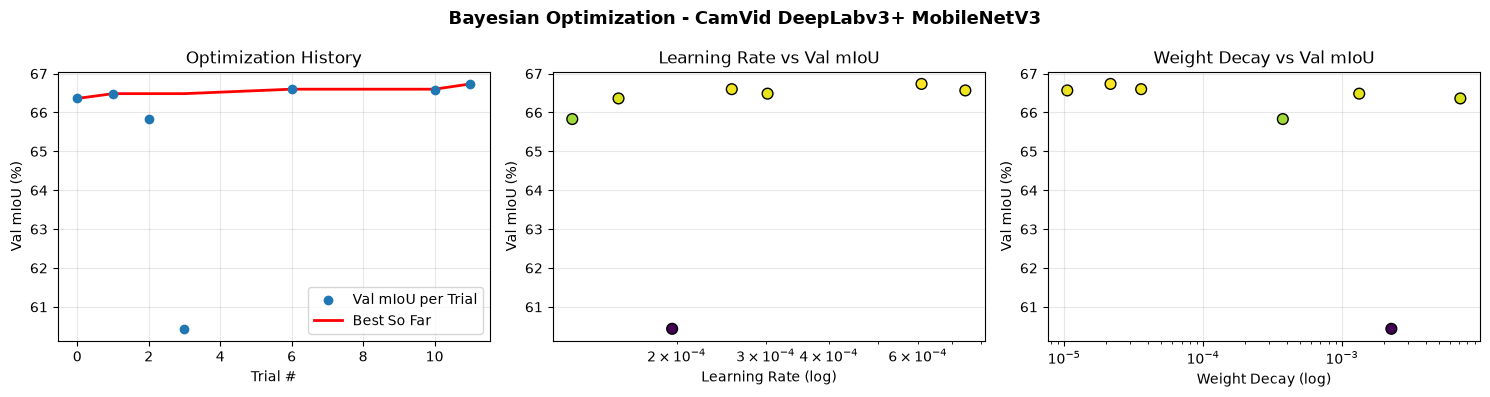

Grafik Bayesian Optimization disimpan ke: C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\src\deep_learning\weights\bayesian_opt_results.png


In [37]:
completed   = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
trial_nums  = [t.number for t in completed]
trial_vals  = [t.value * 100 for t in completed]
best_so_far = np.maximum.accumulate(trial_vals) if trial_vals else []

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].scatter(trial_nums, trial_vals, label="Val mIoU per Trial", zorder=3)
if len(best_so_far) > 0:
    axes[0].plot(trial_nums, best_so_far, color="red", linewidth=2, label="Best So Far")
axes[0].set_title("Optimization History")
axes[0].set_xlabel("Trial #")
axes[0].set_ylabel("Val mIoU (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

lrs = [t.params["lr"] for t in completed]
axes[1].scatter(lrs, trial_vals, c=trial_vals, cmap="viridis", s=60, edgecolor="black")
axes[1].set_xscale("log")
axes[1].set_title("Learning Rate vs Val mIoU")
axes[1].set_xlabel("Learning Rate (log)")
axes[1].set_ylabel("Val mIoU (%)")
axes[1].grid(alpha=0.3)

wds = [t.params["weight_decay"] for t in completed]
axes[2].scatter(wds, trial_vals, c=trial_vals, cmap="viridis", s=60, edgecolor="black")
axes[2].set_xscale("log")
axes[2].set_title("Weight Decay vs Val mIoU")
axes[2].set_xlabel("Weight Decay (log)")
axes[2].set_ylabel("Val mIoU (%)")
axes[2].grid(alpha=0.3)

plt.suptitle("Bayesian Optimization - CamVid DeepLabv3+ MobileNetV3", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(WEIGHTS_DIR / "bayesian_opt_results.png", dpi=120)
plt.show()

print(f"Grafik Bayesian Optimization disimpan ke: {WEIGHTS_DIR / 'bayesian_opt_results.png'}")

### Cell 7.4 — Simpan Hyperparameter Terbaik

In [38]:
best_hp_path = WEIGHTS_DIR / "best_hyperparams.json"
best_payload = {
    "method":        "Bayesian Optimization (Optuna TPE)",
    "n_trials":      N_TRIALS,
    "trial_epochs":  TRIAL_EPOCHS,
    "best_trial":    study.best_trial.number,
    "best_val_miou": round(float(study.best_value), 6),
    "best_val_acc":  study.best_trial.user_attrs.get("best_val_acc", None),
    "best_params":   study.best_params,
}
with best_hp_path.open("w", encoding="utf-8") as f:
    json.dump(best_payload, f, indent=2)

print(f"Hyperparameter terbaik disimpan ke: {best_hp_path}")
print("Langkah berikutnya: gunakan best_hyperparams.json pada train_model.py.")

Hyperparameter terbaik disimpan ke: C:\Users\ASUS\Desktop\Tubes3-PCD\IF4073_PCD_Tugas3\src\deep_learning\weights\best_hyperparams.json
Langkah berikutnya: gunakan best_hyperparams.json pada train_model.py.
